# Assignment 11: Spatial community composition — blobs or stripes?

### **This is an imaginary exercise.**

Maine can protect **1,000 km²** as two compact **blob** parks or two long,
narrow **stripe** parks. Each park covers 500 km². Which design would you
recommend for conserving amphibian diversity?

Follow the analyses in [Lab10](../labs/Lab10-CommunityComposition.ipynb), now
comparing park shapes. You may reuse its code and functions. Complete the code cells 
and short answers. Submit this notebook with its maps, tables, and saved summary CSVs.

## The data

[`ME_BlobStripeParks.geojson`](../data/ME_BlobStripeParks.geojson) contains two
roughly round blobs and two elliptical stripes, five times as long as they
are wide. All four are imaginary, nonoverlapping, and within Maine and the
source sample bounds. Each point already has a park assignment.

Sampling follows Lab10. All real records inside these parks are retained.
All source records in `amphibians.geojson` determine each observed species'
convex hull, its 50 km buffer, and its record-count weight. Each of **50 invented
species** inherits the buffered range and abundance weight of a randomly
sampled observed species. Added points are sampled within those ranges'
intersections with the parks, with counts proportional to the observed or
inherited weights. One point per invented species is reserved. There are
**1,500 total points**, including originals; seed = 597.

`synthetic` identifies generated points; `imaginary_species` identifies invented
taxa.

## 1. Import packages and load the data

Run from `docs/assignments` using the same environment as Lab10.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import entropy
from scipy.spatial.distance import jaccard, braycurtis

AREA_CRS = "EPSG:5070"
COLORS = {"blob": "forestgreen", "stripe": "darkorange"}
designs = ["blob", "stripe"]

In [2]:
features = gpd.read_file("../data/ME_BlobStripeParks.geojson")
parks = features[features.feature_type == "park"].copy()
parks = parks.to_crs(AREA_CRS).set_index("park_id")
records = features[features.feature_type == "occurrence"].copy().to_crs(AREA_CRS)
park_order = list(parks.index)

display(parks[["park_name", "scenario", "area_km2"]])
print("Total occurrence records:", len(records))

,park_name,scenario,area_km2
park_id,,,
B1,Alder Crown Preserve,blob,500.0
B2,Hemlock Hollow Reserve,blob,500.0
S1,Fern Ribbon Preserve,stripe,500.0
S2,Silver Brook Reach,stripe,500.0


Total occurrence records: 1500


## 2. Map the parks and check the comparison

Map the four polygons and their points, using one color per design. Label the
park IDs. A simple map is enough.

Calculate area in km² and show the total area and number of occurrence records
for each design. Keep all records, including generated points and invented
species, in the analyses below.

scenario
blob      1000.000589
stripe    1000.000753
Name: measured_km2, dtype: float64

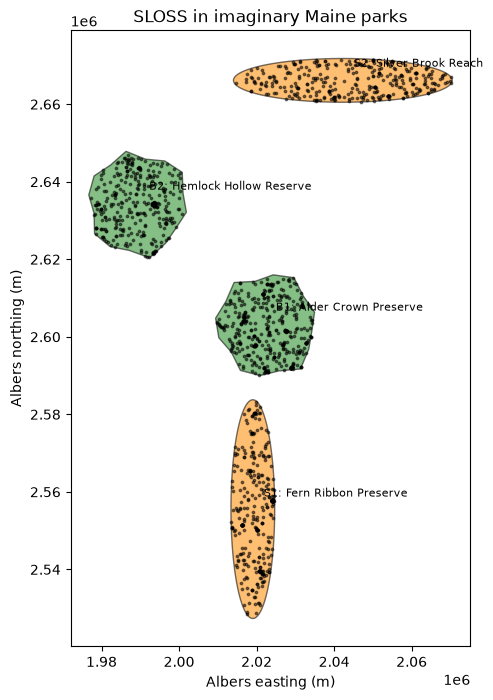

In [3]:
parks["measured_km2"] = parks.area / 1e6
display(parks.groupby("scenario").measured_km2.sum())



# Count records in each design with records.groupby("scenario").size().
records.groupby("scenario").size()
fig, ax = plt.subplots(figsize=(8, 8))

for strategy, group in parks.groupby("scenario"):
    group.plot(ax=ax, color=COLORS[strategy], alpha=0.55, edgecolor="black")

records.plot(ax=ax, color="black", markersize=3, alpha=0.5)
# Plot the parks and occurrence points; label B1, B2, S1, and S2.

for row in parks.itertuples():
    anchor = row.geometry.representative_point()
    ax.annotate(f"{row.Index}: {row.park_name}", (anchor.x, anchor.y),
                xytext=(8, 10), textcoords="offset points", fontsize=8)
ax.set(title="SLOSS in imaginary Maine parks",
       xlabel="Albers easting (m)", ylabel="Albers northing (m)")
plt.show()

**Interpretation:** What is held equal between the designs? What differs besides
shape? Predict which design will capture more species, and explain why.

*Your answer:* What is held equal is that there appear ot be about the same occurance records in each, and the area is the same. What differs is the location of the parks, and the stripes sample a greater spatial scale (i.e spread out across the northing or easting). I predict that the stripes will capture more species, becasue the biggest difference between the stripes and the blobs is that as I mentined above, the stripes stretch across more space. 

## 3. Build the community matrix

Rows are parks; columns are species; entries are record counts. A zero means
no records of that species in that park. It does not establish true absence.

In [4]:
community = pd.crosstab(records.park_id, records.species)
community = community.reindex(park_order, fill_value=0)
presence = community > 0

display(community)
records.species.nunique()

species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Fictotriton alderi,...,Sylvophantoma glacialina,Sylvophantoma hazelii,Sylvophantoma inverna,Sylvophantoma kettleii,Sylvophantoma lichenosa,Sylvophantoma mapleii,Sylvophantoma noctiluca,Sylvophantoma sprucea,Sylvophantoma willowii,Sylvophantoma zephyra
park_id,,,,,,,,,,,,,,,,,,,,,
B1,1,15,47,38,0,37,0,21,1,0,...,0,0,0,3,4,2,1,0,0,8
B2,1,17,39,21,0,26,3,11,5,0,...,0,0,1,5,5,8,0,1,1,5
S1,0,5,47,18,0,22,3,18,6,0,...,1,0,0,2,3,2,0,0,1,5
S2,1,7,11,19,1,13,0,11,4,1,...,0,1,0,3,10,5,1,1,0,8


67

How many species occur in the whole dataset? Choose one species and describe
its distribution among the four parks using its column in `community`.

*Your answer:* There are 67 species in the entire dataset. I am interetsed in Ambystoma maculatum. It looks to have more occurences in Blobs than in stripes, with the highest occurence in Blob2 and the least in Stripe1. 

## 4. Richness, Shannon diversity, and evenness

Use the lab's function below. Shannon uses `scipy.stats.entropy`; larger values
reflect more species, greater evenness, or both.

In [5]:
def diversity(community_counts):
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["n_records", "richness", "shannon"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_present = counts[counts > 0]
        results.loc[unit, "n_records"] = counts.sum()
        if len(species_present) == 0:
            continue
        results.loc[unit, "richness"] = len(species_present)
        results.loc[unit, "shannon"] = entropy(species_present)
    return results

,n_records,richness,shannon,park_name,scenario,evenness
park_id,,,,,,
B1,436.0,51.0,3.323911,Alder Crown Preserve,blob,0.544485
B2,409.0,54.0,3.516299,Hemlock Hollow Reserve,blob,0.623327
S1,328.0,49.0,3.320299,Fern Ribbon Preserve,stripe,0.564666
S2,327.0,57.0,3.711955,Silver Brook Reach,stripe,0.718136


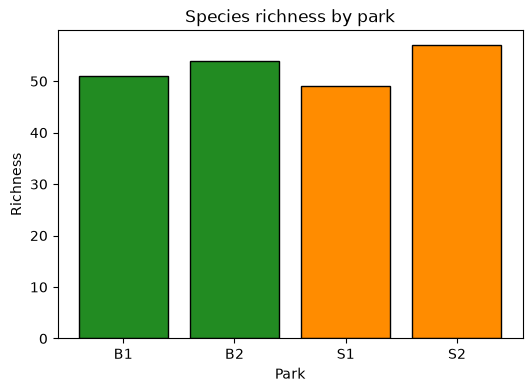

In [6]:
# Calculate park_metrics = diversity(community).
park_metrics = diversity(community)
# Add park names and scenarios from parks.
park_metrics["park_name"] = parks.park_name
park_metrics["scenario"] = parks.scenario
# Add evenness = np.exp(shannon) / richness, as in Lab10.
park_metrics["evenness"] = np.exp(park_metrics["shannon"])/park_metrics["richness"]
# Display the table and make a simple richness or Shannon plot.
display(park_metrics)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(park_metrics.index, park_metrics["richness"],
       color=[COLORS[s] for s in park_metrics["scenario"]],
       edgecolor="black")
ax.set(title="Species richness by park", xlabel="Park", ylabel="Richness")
plt.show()

Does the richest park also have the highest Shannon diversity and evenness?
What would adding 100 records of an already common species do to these measures?

*Your answer:* The richest park is B2, and it does not have the highest shannon diversity or evenness. Adding 100 records of an already common species wouldnot chnage richness becasue it is not adding a new species to the data, it would decrease the shannon index becasue adding these records would make the community more dominated by that species (presumably), and it would also decrease evenness. 

## 5. Alpha, beta, and gamma diversity

Pool the two blob parks, then the two stripe parks. For each design, calculate:

- **Alpha:** mean richness of its two parks.
- **Gamma:** richness in the pooled species list.
- **Multiplicative beta:** gamma divided by alpha.
- Total records and pooled Shannon diversity.

Keep the park rows in `community`; use `design_counts` for the pooled rows.

In [7]:
design_counts = pd.DataFrame(index=designs, columns=community.columns, dtype=float)
for design in designs:
    park_ids = parks[parks.scenario == design].index
    design_counts.loc[design] = community.loc[park_ids].sum()

# Use diversity(design_counts) to start design_metrics.
design_metrics = diversity(design_counts)
# Rename its richness column to gamma_richness.
design_metrics = design_metrics.rename(columns={"richness": "gamma_richness"})
# For each design, find its two rows in park_metrics.
for design in designs:
    local_parks = park_metrics[park_metrics.scenario == design]
    alpha = local_parks.richness.mean()
    gamma = design_metrics.loc[design, "gamma_richness"]
    design_metrics.loc[design, "mean_park_alpha"] = alpha
    design_metrics.loc[design, "beta_ratio"] = gamma / alpha
    
# Calculate mean_park_alpha and beta_ratio, then display design_metrics.

display(design_metrics)

,n_records,gamma_richness,shannon,mean_park_alpha,beta_ratio
blob,845.0,60.0,3.460793,52.5,1.142857
stripe,655.0,63.0,3.606102,53.0,1.188679


Which design has higher gamma diversity? Does alpha or complementarity between
its two parks help explain the result? Why is pooled richness generally smaller
than the sum of the two park richnesses?

List species recorded only in blobs and species recorded only in stripes.
Hint: make a `set` from the species with positive counts in each pooled row;
subtract one set from the other.

*Your answer:* The stripe has higher gamma diversity. The alpha is extemely close for both blob and stripe, so it by itself does not explain the higher gamma. The blob has lower sampling, which could explain the difference. Pooled richness is gnerally smaller than the sum because there is overlap between the two types in terms of species, so there are shared species between the two. 

In [8]:
# Make blob_species and stripe_species from design_counts.
blob_species = set(design_counts.columns[design_counts.loc["blob"] > 0])
stripe_species = set(design_counts.columns[design_counts.loc["stripe"] > 0])

only_blob = sorted(blob_species - stripe_species)
only_stripe = sorted(stripe_species - blob_species)
# Print species unique to each design.
print("Only in blobs:", only_blob)
print("Only in stripes:", only_stripe)

Only in blobs: ['Imaginarana emberi', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Sylvophantoma inverna']
Only in stripes: ['Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton vernalensis', 'Rana arvalis', 'Sylvophantoma cedrina', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii']


### Jaccard dissimilarity

Jaccard compares presence/absence: 0 means identical species lists; 1 means no
shared species. Use `scipy.spatial.distance.jaccard` on rows of `presence`.

In [9]:
print("B1 versus B2:", jaccard(presence.loc["B1"], presence.loc["B2"]))

# Build jaccard_distances, a four-by-four table, as in Lab10.
# Use nested loops over park_order and jaccard(presence.loc[a], presence.loc[b]).
jaccard_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        jaccard_distances.loc[park_a, park_b] = jaccard(
            presence.loc[park_a], presence.loc[park_b]
        )
# Display the table.
display(jaccard_distances.round(2))

B1 versus B2: 0.25


,B1,B2,S1,S2
B1,0.00,0.25,0.25,0.20
B2,0.25,0.00,0.28,0.27
S1,0.25,0.28,0.00,0.32
S2,0.20,0.27,0.32,0.00


Compare B1–B2 with S1–S2. Which design's two parks have more different species
lists? Does that agree with the beta ratios? Explain why Jaccard alone cannot
distinguish species replacement from differences in richness.

*Your answer:* The stripes paris have more different species becasue the strip pair has a higher value of 0.32 compared with the blob paor of 0.25.This does agree with the beta ratios becasue stripes beta was higher. Jaccard alone cannot distinguish species replacement from differences in richness because jaccard can only tell you how differnt speceis lists are, not the reason why they are different. 

### Bray–Curtis dissimilarity

Use `scipy.spatial.distance.braycurtis` on record counts. Make a second
four-by-four table, `bray_curtis_distances`.

Then repeat the B1–B2 and S1–S2 comparisons using **relative frequencies**:
divide each park's species counts by its total records before calling
`braycurtis`.

In [10]:
print("B1 versus B2:", braycurtis(community.loc["B1"], community.loc["B2"]))

# Build and display bray_curtis_distances using the Jaccard loop pattern.
bray_curtis_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        bray_curtis_distances.loc[park_a, park_b] = braycurtis(
            community.loc[park_a], community.loc[park_b]
        )
display(bray_curtis_distances.round(2))
# For each within-design pair, divide each row by its sum and compare again.
a_counts = community.loc["B1"]
b_counts = community.loc["B2"]
a_frequencies = a_counts / a_counts.sum()
b_frequencies = b_counts / b_counts.sum()
print("B1 versus B2, relative frequencies:", braycurtis(a_frequencies, b_frequencies))

a_counts = community.loc["S1"]
b_counts = community.loc["S2"]
a_frequencies = a_counts / a_counts.sum()
b_frequencies = b_counts / b_counts.sum()
print("S1 versus S2, relative frequencies:", braycurtis(a_frequencies, b_frequencies))

B1 versus B2: 0.19763313609467456


,B1,B2,S1,S2
B1,0.00,0.20,0.24,0.33
B2,0.20,0.00,0.25,0.27
S1,0.24,0.25,0.00,0.30
S2,0.33,0.27,0.30,0.00


B1 versus B2, relative frequencies: 0.19325497409210204
S1 versus S2, relative frequencies: 0.3037032893264713


Do Jaccard and Bray–Curtis tell the same story? What information does Bray–Curtis
add? Why can unequal record totals affect its values, and what changes when
you use relative frequencies?

*Your answer:* Yes, both show that the stripe comparison has a higher dissimilarity. Bray curtis accoutns for differences in abundance. Unequal record totals can affects its values because the distance can come from the sampling effort, so by using relative frequencies you are normalizing the sampling effort relative to that specific park. 

## 6. Compare equal numbers of records

Use record-based rarefaction to check whether the pooled richness comparison
persists when both designs contribute the same number of records. Draw without
replacement and repeat **300 times**, following the lab's loop.

For each design, report mean richness and the 2.5th and 97.5th percentiles of
the draws. These percentiles describe resampling variation, not confidence
intervals for true richness. Equal record counts do not establish equal survey
effort or detectability.

In [11]:
equal_n = records.groupby("scenario").size().min()
rarefaction = pd.DataFrame()

#For each design, select its records and start an empty richness_samples list.
# Repeat 300 times:
for design in designs:
    design_records = records[records.scenario == design]
    richness_samples = []
    for repeat in range(300):
        sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
        richness_samples.append(sample.species.nunique())
#     Append sample.species.nunique() to richness_samples.
# Store records_drawn, mean_richness, q025, and q975 in rarefaction.
    rarefaction.loc[design, "records_drawn"] = equal_n
    rarefaction.loc[design, "mean_richness"] = np.mean(richness_samples)
    rarefaction.loc[design, "q025"] = np.quantile(richness_samples, 0.025)
    rarefaction.loc[design, "q975"] = np.quantile(richness_samples, 0.975)
# Use np.mean and np.quantile, then display the table.
display(rarefaction)

,records_drawn,mean_richness,q025,q975
blob,655.0,57.423333,54.0,60.0
stripe,655.0,63.000000,63.0,63.0


Does equalizing record numbers change your preference? Which original sampling
biases and simulation assumptions remain?

*Your answer:* This does not change my preference. Stripe still captured more speices in the percentile ranges. Sampling biases and simulation assumptions that still remain could be that the same record counts does not neccesarily mean equal survey effort. 

## 7. Rarity and restriction within the sample

Build `species_context` with each species' total records and number of occupied
parks. Define **record-rare** as at most five records across all four parks.
Use the same four parks as the reference throughout this section.

In [12]:
species_context = pd.DataFrame()
for species in community.columns:
    counts = community[species]
    species_context.loc[species, "n_records"] = counts.sum()
    species_context.loc[species, "parks_recorded"] = sum(counts > 0)

rare_rows = species_context[species_context.n_records <= 5]
rare_species = list(rare_rows.index)
display(species_context)

,n_records,parks_recorded
Ambystoma laterale,3.0,3.0
Ambystoma maculatum,44.0,4.0
Anaxyrus americanus,144.0,4.0
Aquarana clamitans,96.0,4.0
Aquarana septentrionalis,1.0,1.0
...,...,...
Sylvophantoma mapleii,17.0,4.0
Sylvophantoma noctiluca,2.0,2.0
Sylvophantoma sprucea,2.0,2.0
Sylvophantoma willowii,2.0,2.0


Reuse `restriction_metrics` from Lab10 to calculate each park's:

- Sample-exclusive richness: species recorded in only one of the four parks.
- Weighted endemism proxy (WE): sum of `1 / parks_recorded` for species present.
- Corrected WE (CWE): WE divided by park richness.
- Record-rare richness: number of record-rare species present.

Compare the two designs' **pooled record-rare richness** as well: count each rare
species once per design, even if both parks record it.

In [13]:
# Copy the restriction_metrics function from Lab10.
def restriction_metrics(community_counts):
    occupancy = (community_counts > 0).sum(axis=0)
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["sample_exclusive", "we_proxy", "cwe_proxy", "record_rare_richness"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_here = counts[counts > 0].index
        if len(species_here) == 0:
            continue
        exclusive = 0
        rare = 0
        weighted_endemism = 0
        for species in species_here:
            occupied_units = occupancy[species]
            weighted_endemism += 1 / occupied_units
            if occupied_units == 1:
                exclusive += 1
            if species in rare_species:
                rare += 1
        results.loc[unit, "sample_exclusive"] = exclusive
        results.loc[unit, "we_proxy"] = weighted_endemism
        results.loc[unit, "cwe_proxy"] = weighted_endemism / len(species_here)
        results.loc[unit, "record_rare_richness"] = rare
    return results
# Calculate park_restriction = restriction_metrics(community).
park_restriction = restriction_metrics(community)
# Display park_metrics.join(park_restriction).
display(park_metrics.join(park_restriction))

# For each design, loop through rare_species.
# Count a species once if design_counts.loc[design, species] > 0.
for design in designs:
    count = 0
    for species in rare_species:
        if design_counts.loc[design, species] > 0:
            count += 1
    print(f"{design}: pooled record-rare richness = {count}")


,n_records,richness,shannon,park_name,scenario,evenness,sample_exclusive,we_proxy,cwe_proxy,record_rare_richness
park_id,,,,,,,,,,
B1,436.0,51.0,3.323911,Alder Crown Preserve,blob,0.544485,1.0,14.833333,0.290850,9.0
B2,409.0,54.0,3.516299,Hemlock Hollow Reserve,blob,0.623327,3.0,17.666667,0.327160,13.0
S1,328.0,49.0,3.320299,Fern Ribbon Preserve,stripe,0.564666,2.0,15.000000,0.306122,8.0
S2,327.0,57.0,3.711955,Silver Brook Reach,stripe,0.718136,4.0,19.500000,0.342105,17.0


blob: pooled record-rare richness = 17
stripe: pooled record-rare richness = 20


Does a park with high WE also have high CWE? Which design captures more
record-rare species? Are any sample-exclusive species relatively well recorded?
Explain why these results do not establish that a species is endemic to a park
or has a small population. How might invented species with few generated
records affect these metrics?

*Your answer:* Yes, a park with high WE also has high CWE. Stripe captures more record-rare species (20 compared to 17). These reuslts do not establish that a species is endemic to a aprk or has a small population because these parks are arbitray boarder markers, just becasue a species was or was not recorded in one of them does not mean that it cannot be found elsewhere in Maine. Invented species with few generated records could effect these metrics because it could call a species a record-rare whihc is just an artifacte of how the data was generated, not what is actually true.  

## 8. Save results and make a recommendation

Save `park_metrics.join(park_restriction)`, `design_metrics`, `species_context`,
`jaccard_distances`, `bray_curtis_distances`, and `rarefaction` as CSVs.

In [14]:
output_dir = Path("outputs/Assignment11")
output_dir.mkdir(parents=True, exist_ok=True)

# Save each table with .to_csv(output_dir / "table_name.csv").
park_metrics.join(park_restriction).to_csv(output_dir / "park_metrics.csv")
design_metrics.to_csv(output_dir / "design_metrics.csv")
species_context.to_csv(output_dir / "species_context.csv")

jaccard_distances.to_csv(output_dir / "park_jaccard.csv")
bray_curtis_distances.to_csv(output_dir / "park_bray_curtis.csv")
rarefaction.to_csv(output_dir / "rarefaction.csv")

### Conservation recommendation (400–600 words)

Recommend blobs, stripes, or explain why the evidence does not favor one.
Support your conclusion with your map and numerical results. Address:

1. Alpha, gamma, beta, and the species contributed by each design.
2. Shannon diversity, evenness, Jaccard, and Bray–Curtis: which comparisons
   influence your decision, and why?
3. Whether rarefaction changes the result, and what rarity and restriction add.
4. Why these four locations cannot isolate a causal effect of shape. The sampler
   includes geographic ranges and reporting patterns, but no explicit edge
   effects, dispersal, or population persistence. What additional biological
   evidence or repeated park placements would help test your explanation?

*Your recommendation:*
The commendation I am giving is for stripes. 

Alpha, Beta, and Gamma: Both the stripe and the blob design protect the same amount of land (1000km^2) so any difference we see in values is not based on size. The average park in each design has about the same number of species (52.5 for blobs and 53 for stripes), this is the alpha diversity. The two stripe parks together have more species (63) than the two blob parks (60), this is the gamma diversity. Beta diversity is also higher for stripes (1.19 versus 1.14) which means the two stripe parks have more different species than each other so they cumulatively have a bigger list. 
Comparison Influence: Pooled shannon diversity is higher for stripes at 3.61 versus 3.46. Jaccard and Bray-Curtis were the most helpful comparisons used because they better show how different the two parks are in terms of their design. The stripe parks are more different from each other (Jaccard 0.32 versus 0.25, Bray-Curtis 0.30 versus 0.20). This comparison matches the beta result. The evenness result did not show a clear difference between designs so I did not use it to consider my recommendation. 
Ratification, rarity, and restriction: Blobs had more records than stripes (845 v 655), so using rarefaction was necessary to make sure more records did not mean more species. Rarefaction did not change the result with stripes still having more species. Stripes had more rare species (20 versus 17) and more restricted species (6 v4)
Why we can’t say shape is the cause: One of the biggest things to note is this is a simulation, and these are only four made up parks in one made up landscape, and may not reflect what would be found in the real world. The stripes may do better because they cross more habitat, not because of shape. For example, a rectangle shape might have had the same results. Stripes are also more biased to edge effects, so species that do well better on the interior of a habitat would have been left out. Additional biological information that would help me test this explanation would be a map of habitat to see the range of habitat types that stripes and blobs cover, and maybe information on how species move between locations. 
